# FlowVQ on MNIST

A VQ-VAE with a FlowVQ codebook, compared with a standard VQ-VAE. Use a GPU runtime.

In [1]:
!git clone -q https://github.com/friolero/FlowVQ.git
%cd FlowVQ
!pip install -q zuko einops

In [2]:
from types import SimpleNamespace

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets
from tqdm.auto import tqdm

from flowvq import FlowQuantizer
from viz_utils import vis_3d_codebook

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Config

As in `image_tasks/configs/cifar10/flow_tokenizer_cifar10_K1024Z10.yaml`, except `fm_update_every`.

In [3]:
cfg = SimpleNamespace(
    codebook_size=1024,
    token_size=10,
    batch_size=128,
    lr=1e-4,
    weight_decay=1e-4,
    max_grad_norm=1.0,
    total_steps=5001,
    flow_start_step=1000,  # auto-encoder warm-up, then codebook initialization
    fm_steps=2000,  # steps per initialization round
    fm_patience=5,  # rounds without improvement before stopping
    fm_update_every=100,  # online codebook update interval
    fm_optim_steps=5,  # Lloyd iterations per update
    self_correction=True,  # Lloyd refinement on dense flow samples
    online_correction=False,  # add the VQ-VAE codebook loss
    # The paper uses adaptive dopri5. Here Euler-12 matches it (mean test MSE 0.00315 for both,
    # 2 seeds) with a ~17x faster flow push-forward.
    ode_solver="euler",  # "dopri5": adaptive, as in the paper; "euler": fixed steps
    ode_steps=12,  # Euler integration step if ode_solver == 'euler' 
    n_eval_batches=10,
    seed=0,
)

## Model

VQ-VAE encoder/decoder (van den Oord et al., 2017) with a FlowVQ or a standard VQ-VAE quantizer.

In [4]:
class ResidualStack(nn.Module):
    def __init__(self, channels, res_channels, n_blocks):
        super().__init__()
        self.blocks = nn.ModuleList(
            nn.Sequential(
                nn.ReLU(),
                nn.Conv2d(channels, res_channels, 3, padding=1),
                nn.ReLU(),
                nn.Conv2d(res_channels, channels, 1),
            )
            for _ in range(n_blocks)
        )

    def forward(self, x):
        for block in self.blocks:
            x = x + block(x)
        return F.relu(x)


def encoder(d, h=128, r=32):  # 28x28 image -> (d, 7, 7) latents
    return nn.Sequential(
        nn.Conv2d(1, h // 2, 4, stride=2, padding=1),
        nn.ReLU(),
        nn.Conv2d(h // 2, h, 4, stride=2, padding=1),
        nn.ReLU(),
        nn.Conv2d(h, h, 3, padding=1),
        ResidualStack(h, r, 2),
        nn.Conv2d(h, d, 1),
    )


def decoder(d, h=128, r=32):  # (d, 7, 7) latents -> 28x28 image
    return nn.Sequential(
        nn.Conv2d(d, h, 3, padding=1),
        ResidualStack(h, r, 2),
        nn.ConvTranspose2d(h, h // 2, 4, stride=2, padding=1),
        nn.ReLU(),
        nn.ConvTranspose2d(h // 2, 1, 4, stride=2, padding=1),
    )


class VectorQuantizer(nn.Module):
    """Standard VQ-VAE quantizer (baseline)."""

    def __init__(self, k_dim, x_dim, commitment_cost=0.25):
        super().__init__()
        self.commitment_cost = commitment_cost
        self.embedding = nn.Embedding(k_dim, x_dim)
        self.embedding.weight.data.uniform_(-1.0 / k_dim, 1.0 / k_dim)

    @property
    def codebook(self):
        return self.embedding.weight.data

    def forward(self, z):
        b, d, h, w = z.shape
        inds = torch.cdist(z.permute(0, 2, 3, 1).reshape(-1, d), self.embedding.weight).argmin(1)
        z_q = self.embedding(inds).view(b, h, w, d).permute(0, 3, 1, 2)
        loss = F.mse_loss(z_q, z.detach()) + self.commitment_cost * F.mse_loss(z, z_q.detach())
        return z + (z_q - z).detach(), dict(quantizer_loss=loss, min_encoding_indices=inds.view(b, h, w))

    @torch.no_grad()
    def get_vq_loss(self, ze_batches):
        z = torch.cat([z_e.permute(0, 2, 3, 1).reshape(-1, z_e.shape[1]) for z_e in ze_batches])
        return (self.codebook[torch.cdist(z, self.codebook).argmin(1)] - z).abs().mean()


class VQModel(nn.Module):
    def __init__(self, quantizer):
        super().__init__()
        self.encoder = encoder(cfg.token_size)
        if quantizer == "flowvq":
            self.quantize = FlowQuantizer(
                x_dim=cfg.token_size,
                k_dim=cfg.codebook_size,
                self_correction=cfg.self_correction,
                online_correction=cfg.online_correction,
                ode_solver=cfg.ode_solver,
                ode_steps=cfg.ode_steps,
            )
        else:
            self.quantize = VectorQuantizer(cfg.codebook_size, cfg.token_size)
        self.decoder = decoder(cfg.token_size)

    def forward(self, x):
        z_q, result = self.quantize(self.encoder(x))
        return self.decoder(z_q), result

## Data and evaluation

In [5]:
def load_mnist(train):
    x = datasets.MNIST("data", train=train, download=True).data
    return (x.float() / 255).unsqueeze(1).to(device)


train_x, test_x = load_mnist(True), load_mnist(False)


def train_batches(x, bs):
    while True:  # reshuffle every epoch
        perm = torch.randperm(len(x), device=x.device)
        for i in range(len(x) // bs):
            yield x[perm[i * bs : (i + 1) * bs]]


@torch.no_grad()
def eval_latents(model):
    bs = cfg.batch_size
    return [model.encoder(test_x[i * bs : (i + 1) * bs]) for i in range(cfg.n_eval_batches)]


@torch.no_grad()
def evaluate(model):
    """Test MSE and number of codes used."""
    model.eval()
    sq_err, used = 0.0, set()
    for x in test_x.split(cfg.batch_size):
        recon, result = model(x)
        sq_err += F.mse_loss(recon, x, reduction="sum").item()
        used.update(result["min_encoding_indices"].unique().tolist())
    model.train()
    return sq_err / test_x.numel(), len(used)


def show_codebook(zes, codebook, title):
    fig = vis_3d_codebook(torch.cat(zes), codebook)
    fig.set_size_inches(15, 5)
    fig.suptitle(title)
    plt.show()


@torch.no_grad()
def show_reconstructions(model, n=10):
    model.eval()
    x = test_x[:n]
    recon = model(x)[0].clamp(0, 1)
    model.train()
    fig, axes = plt.subplots(2, n, figsize=(n, 2.2))
    for j in range(n):
        for row, img in enumerate((x[j, 0], recon[j, 0])):
            axes[row, j].imshow(img.cpu(), cmap="gray", vmin=0, vmax=1)
            axes[row, j].axis("off")
    plt.show()

## Codebook initialization

As `init_flowvq` in `image_tasks/scripts/train_tokenizer.py`.

In [6]:
def fit_rounds(step_fn, eval_fn, name):
    """Run rounds of fm_steps until eval_fn has not improved for fm_patience rounds."""
    i, best, patience = 0, None, 0
    while True:
        for _ in tqdm(range(cfg.fm_steps), desc=f"{name} round {i}", leave=False):
            step_fn()
        vq_loss = eval_fn()
        if best is None:
            best = vq_loss
        elif vq_loss >= best - 1e-3:
            patience += 1
            if patience >= cfg.fm_patience:
                return
        else:
            best, patience = vq_loss, 0
        print(f"{name} round {i}: vq loss {vq_loss:.4f}, patience {patience}")
        i += 1


def init_flowvq(model, train_iter, zes):
    q = model.quantize
    opt = torch.optim.AdamW(q.parameters(), lr=1e-4)

    def fm_step():  # flow matching on encoder latents
        with torch.no_grad():
            z_e = model.encoder(next(train_iter))
        opt.zero_grad()
        q.loss(z_e).backward()
        opt.step()

    def flow_codebook_loss():  # push the Sobol prior through the flow
        q.update_codebook(optim_steps=0)
        return q.get_vq_loss(zes)

    def self_correction_step():  # move codes towards their assigned latents
        with torch.no_grad():
            z_e = model.encoder(next(train_iter))
        z_q = q.embedding(q.quantize(z_e)[0]).permute(0, 3, 1, 2)
        opt.zero_grad()
        (z_q - z_e).square().mean().backward()
        opt.step()

    fit_rounds(fm_step, flow_codebook_loss, "flow matching")
    if q.self_correction:
        fit_rounds(self_correction_step, lambda: q.get_vq_loss(zes), "self-correction")
        with torch.no_grad():
            q.prior_codebook = q.flow.encode(q.codebook)  # refined codes back to the prior
    q.initialized = True

## Training

In [7]:
def train(quantizer="flowvq"):
    torch.manual_seed(cfg.seed)
    flowvq = quantizer == "flowvq"
    model = VQModel(quantizer).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    train_iter = train_batches(train_x, cfg.batch_size)
    start = cfg.flow_start_step

    for step in tqdm(range(cfg.total_steps), desc=quantizer):
        if flowvq and step == start:  # FlowVQ: auto-encoder until here, then initialize the codebook
            print(f"Auto-encoder test MSE: {evaluate(model)[0]:.5f}")
            init_flowvq(model, train_iter, eval_latents(model))
        elif flowvq and step > start and (step - start) % cfg.fm_update_every == 0:
            model.quantize.update_codebook_parallel(rank=0, world_size=1, optim_steps=cfg.fm_optim_steps)

        x = next(train_iter)
        recon, result = model(x)
        loss = F.mse_loss(recon, x) + result["quantizer_loss"]
        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), cfg.max_grad_norm)
        opt.step()

    mse, used = evaluate(model)
    print(f"{quantizer} test MSE: {mse:.5f}, codebook usage: {used}/{cfg.codebook_size}")
    show_codebook(eval_latents(model), model.quantize.codebook, f"{quantizer} codebook after training")
    show_reconstructions(model)
    return mse, used

## FlowVQ

t-SNE of latents (●) and codes (▲); the right panel overlays both.

Auto-encoder test MSE: 0.00273


flow matching round 0: vq loss 0.0692, patience 0


flow matching round 1: vq loss 0.0655, patience 0


flow matching round 2: vq loss 0.0643, patience 0


flow matching round 3: vq loss 0.0635, patience 1


...

self-correction round 2: vq loss 0.0474, patience 1


self-correction round 3: vq loss 0.0472, patience 2


self-correction round 4: vq loss 0.0470, patience 3


self-correction round 5: vq loss 0.0469, patience 4


flowvq test MSE: 0.00325, codebook usage: 1024/1024


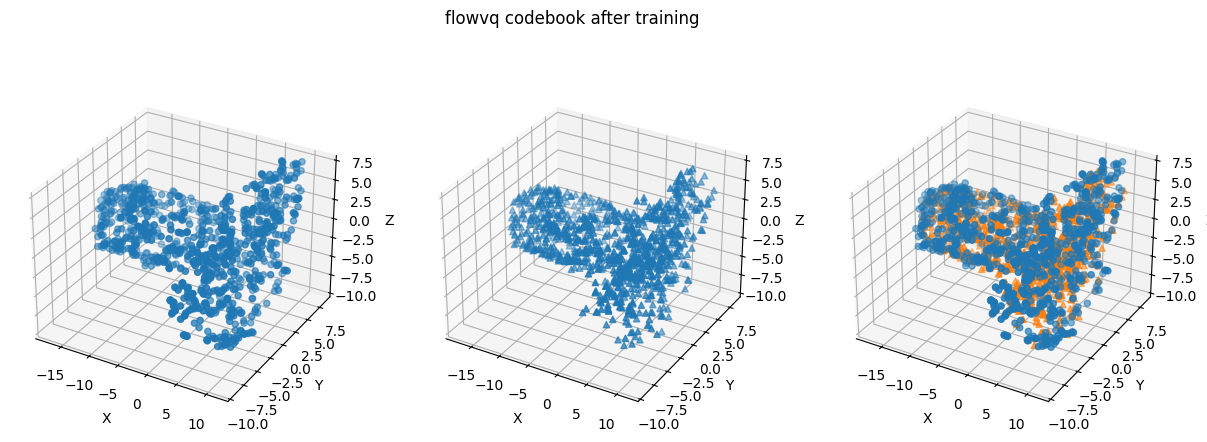

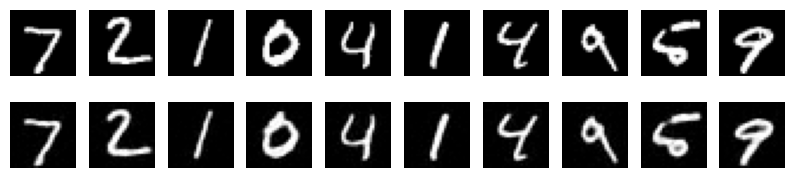

In [8]:
results = {"FlowVQ": train("flowvq")}

## VQ-VAE baseline

vqvae test MSE: 0.00464, codebook usage: 109/1024


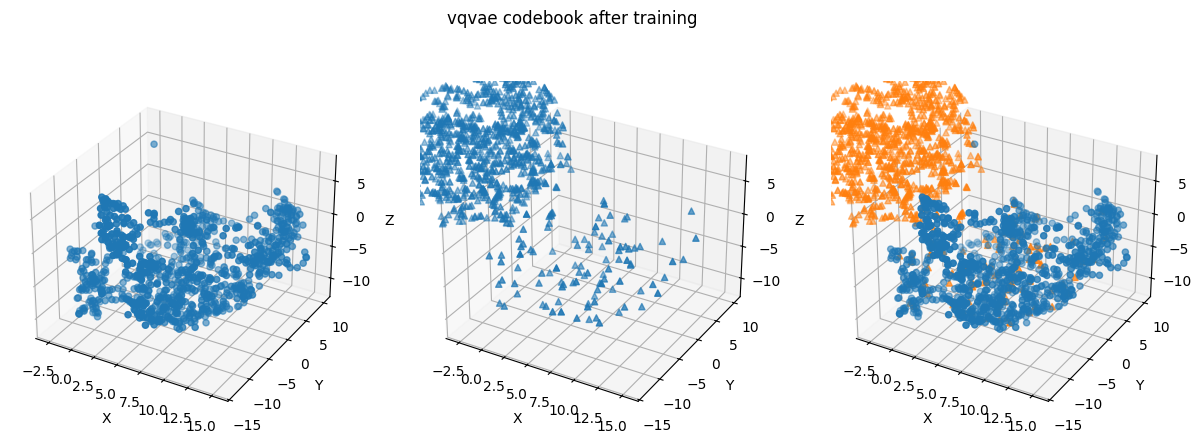

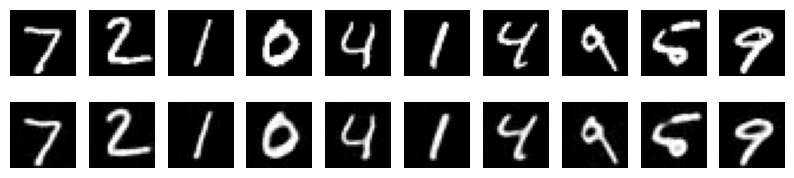

In [9]:
results["VQ-VAE"] = train("vqvae")

## Comparison

In [10]:
print(f"{'':8s} {'test MSE':>9s} {'codes used':>11s}")
for name, (mse, used) in results.items():
    print(f"{name:8s} {mse:9.5f} {used:6d}/{cfg.codebook_size}")

          test MSE  codes used
FlowVQ     0.00325   1024/1024
VQ-VAE     0.00464    109/1024
